In [ ]:
# Libraries
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error


--- 

# EDA

In [2]:
df = pd.read_csv("noah_regional_dengue_master.csv")

print(df.shape)
print(df.head())
print(df.dtypes)
print(df.isna().sum())
print(df.duplicated().sum())
print(df["region"].value_counts())

(7072, 9)
  region  year  week  dengue_cases  rainfall_estimate  temperature_era5  \
0  BARMM  2016     1            28               7.45         24.800019   
1  BARMM  2016     2            32               6.25         24.898520   
2  BARMM  2016     3            30               3.45         25.131403   
3  BARMM  2016     4            36               4.27         24.902053   
4  BARMM  2016     5            27               4.88         25.511344   

   specific_humidity_era5  rainfall_approximated_flag  plausibility_flag  
0               16.393187                           1                  0  
1               16.865840                           1                  0  
2               15.779174                           1                  0  
3               15.019548                           1                  0  
4               15.852063                           1                  0  
region                         object
year                            int64
week         

In [3]:
keys = ["region", "year", "week"]

duplicates = df[df.duplicated(keys, keep=False)]
print("Duplicate region-weeks:", len(duplicates))

print("Invalid week numbers:")
print(df.loc[~df["week"].between(1, 53), keys])

print("Negative dengue counts:")
print(df.loc[df["dengue_cases"] < 0])

weather_cols = [
    "rainfall_estimate",
    "temperature_era5",
    "specific_humidity_era5"
]

print("Negative weather values:")
print(df[weather_cols].lt(0).sum())

print("Rainfall approximated flag:")
print(df["rainfall_approximated_flag"].value_counts(dropna=False))

print("Plausibility flag:")
print(df["plausibility_flag"].value_counts(dropna=False))

Duplicate region-weeks: 0
Invalid week numbers:
Empty DataFrame
Columns: [region, year, week]
Index: []
Negative dengue counts:
Empty DataFrame
Columns: [region, year, week, dengue_cases, rainfall_estimate, temperature_era5, specific_humidity_era5, rainfall_approximated_flag, plausibility_flag]
Index: []
Negative weather values:
rainfall_estimate         0
temperature_era5          0
specific_humidity_era5    0
dtype: int64
Rainfall approximated flag:
rainfall_approximated_flag
1    7072
Name: count, dtype: int64
Plausibility flag:
plausibility_flag
0    7066
1       6
Name: count, dtype: int64


In [4]:
for region, group in df.groupby("region"):
    group = group.sort_values(["year", "week"])

    observed = len(group)
    distinct_weeks = len(group[["year", "week"]].drop_duplicates())

    print(
        region,
        "rows =", observed,
        "distinct region-weeks =", distinct_weeks
    )

BARMM rows = 416 distinct region-weeks = 416
CAR rows = 416 distinct region-weeks = 416
MIMAROPA rows = 416 distinct region-weeks = 416
NCR rows = 416 distinct region-weeks = 416
REGION I rows = 416 distinct region-weeks = 416
REGION II rows = 416 distinct region-weeks = 416
REGION III rows = 416 distinct region-weeks = 416
REGION IV-A rows = 416 distinct region-weeks = 416
REGION IX rows = 416 distinct region-weeks = 416
REGION V rows = 416 distinct region-weeks = 416
REGION VI rows = 416 distinct region-weeks = 416
REGION VII rows = 416 distinct region-weeks = 416
REGION VIII rows = 416 distinct region-weeks = 416
REGION X rows = 416 distinct region-weeks = 416
REGION XI rows = 416 distinct region-weeks = 416
REGION XII rows = 416 distinct region-weeks = 416
REGION XIII rows = 416 distinct region-weeks = 416


In [5]:
print(
    df.groupby("rainfall_approximated_flag")[
        ["dengue_cases", "rainfall_estimate"]
    ].agg(["count", "mean", "min", "max"])
)

print(
    df.groupby("plausibility_flag")[
        ["dengue_cases"] + weather_cols
    ].agg(["count", "mean", "min", "max"])
)

                           dengue_cases                        \
                                  count        mean min   max   
rainfall_approximated_flag                                      
1                                  7072  307.404695   1  4868   

                           rainfall_estimate                           
                                       count       mean   min     max  
rainfall_approximated_flag                                             
1                                       7072  53.044094  0.69  343.72  
                  dengue_cases                       rainfall_estimate  \
                         count        mean min   max             count   
plausibility_flag                                                        
0                         7066  307.517407   1  4868              7066   
1                            6  174.666667   7   583                 6   

                                           temperature_era5             \
      

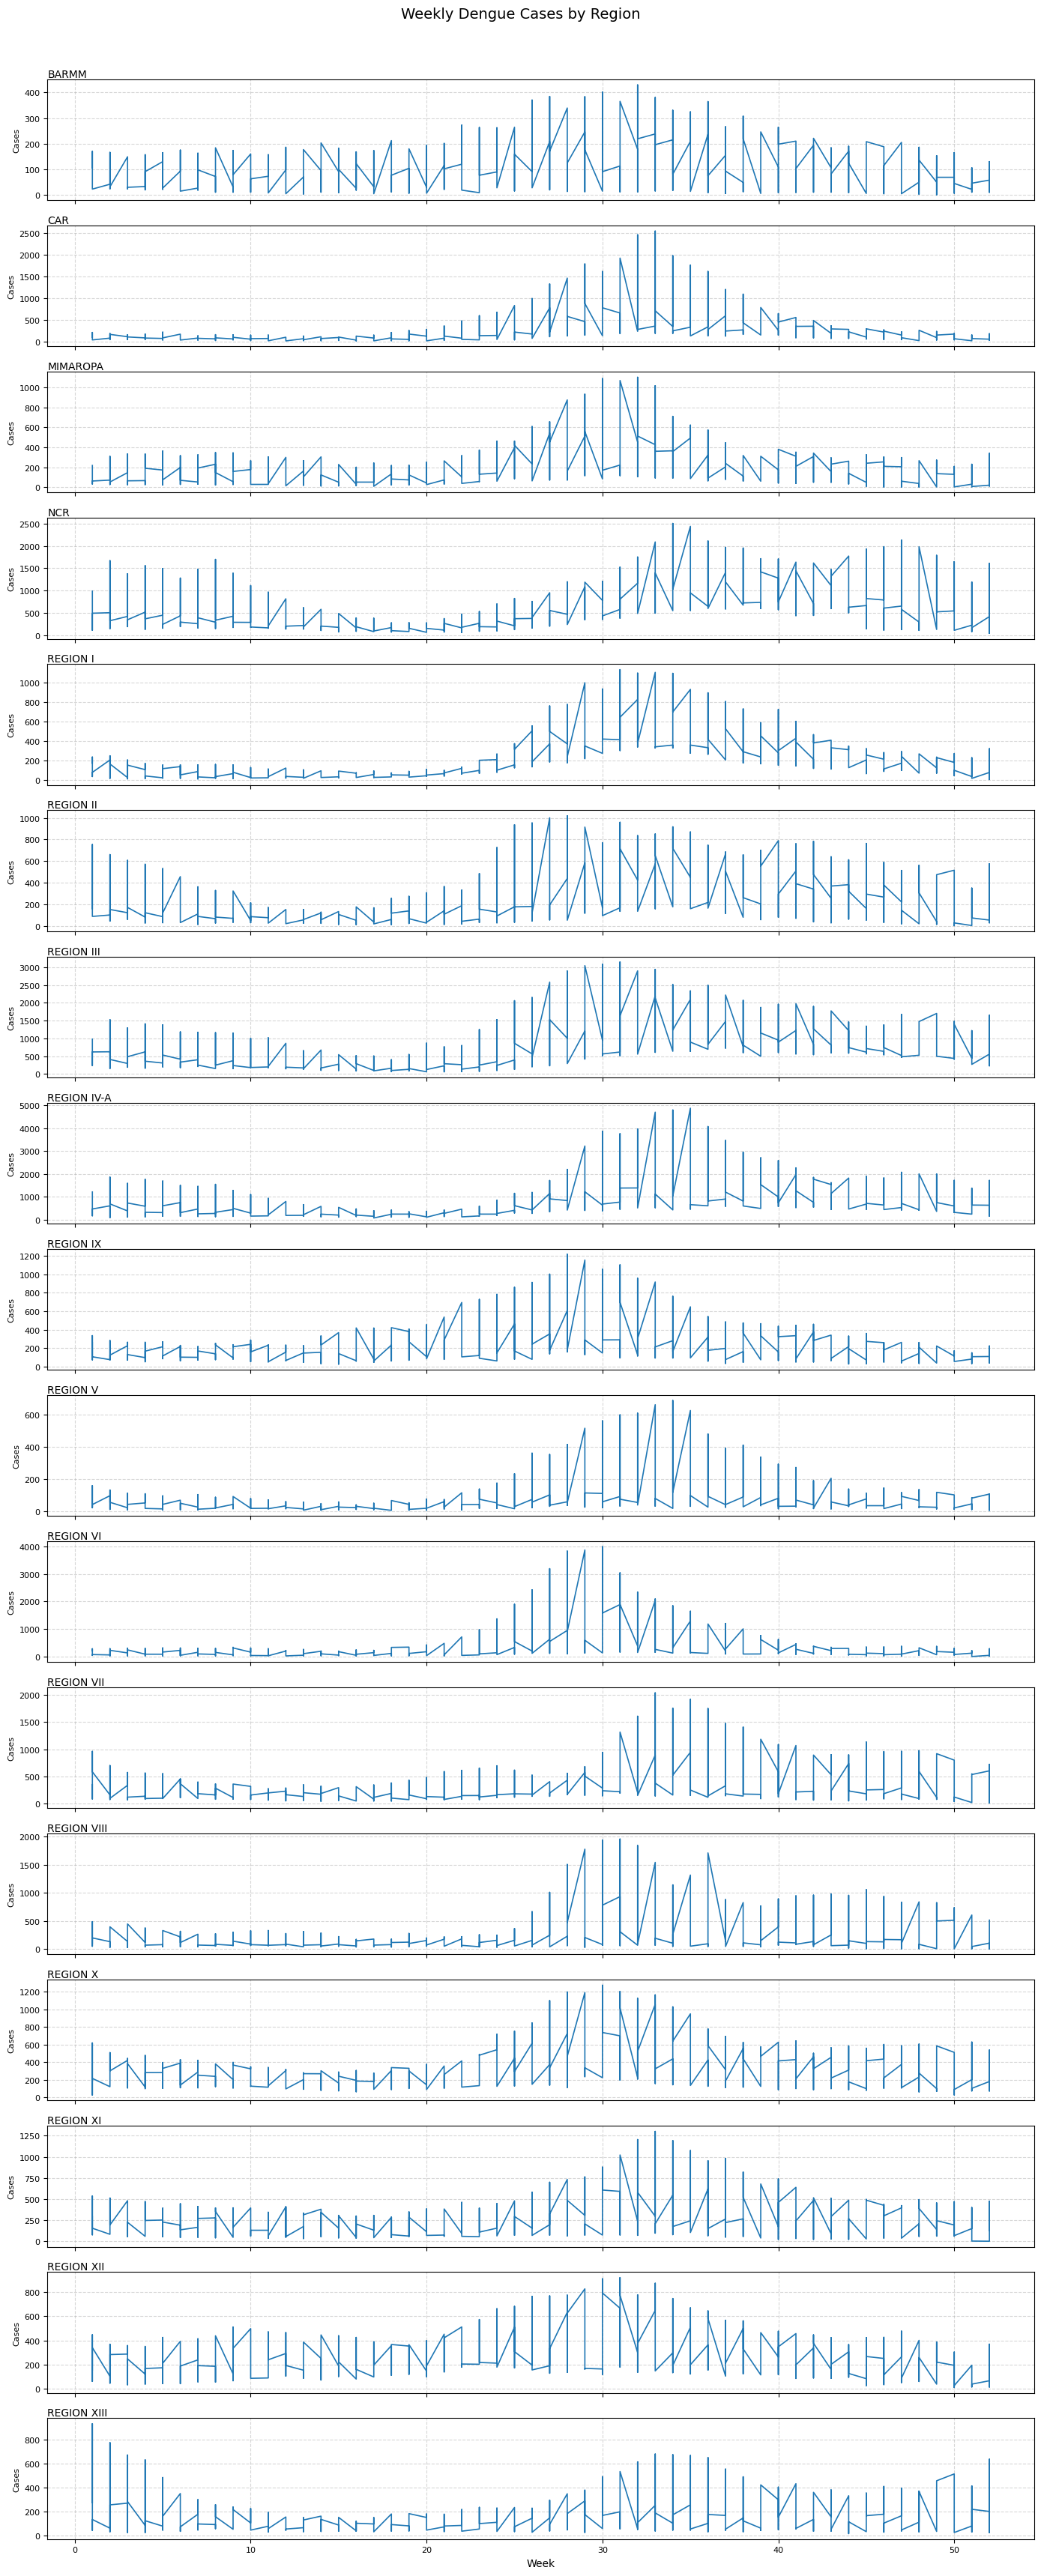

In [8]:
# Get all unique regions
regions = df["region"].unique()
n_regions = len(regions)

# Create a vertical stack of subplots with a shared x-axis
fig, axes = plt.subplots(nrows=n_regions, ncols=1, figsize=(14, 2 * n_regions), sharex=True)

for ax, region in zip(axes, regions):
    subset = df[df["region"] == region].sort_values("week")
    ax.plot(subset["week"], subset["dengue_cases"], color="tab:blue", linewidth=1.2)
    ax.set_title(region, fontsize=10, loc="left", pad=2)
    ax.set_ylabel("Cases", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.grid(True, linestyle="--", alpha=0.5)

# Set x-label on the bottom subplot
axes[-1].set_xlabel("Week", fontsize=10)

plt.suptitle("Weekly Dengue Cases by Region", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

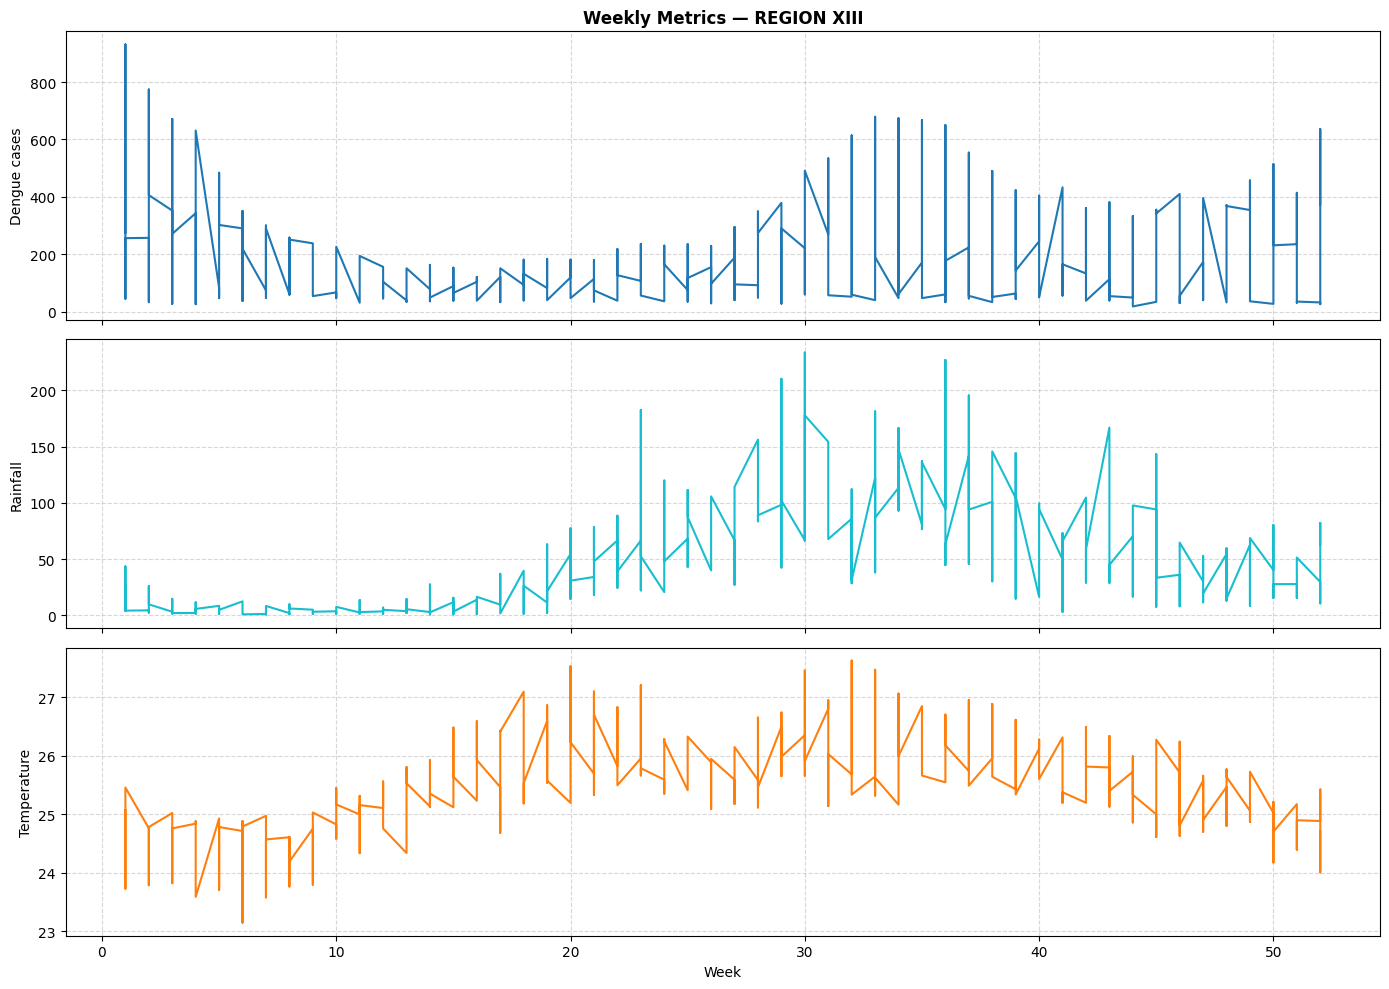

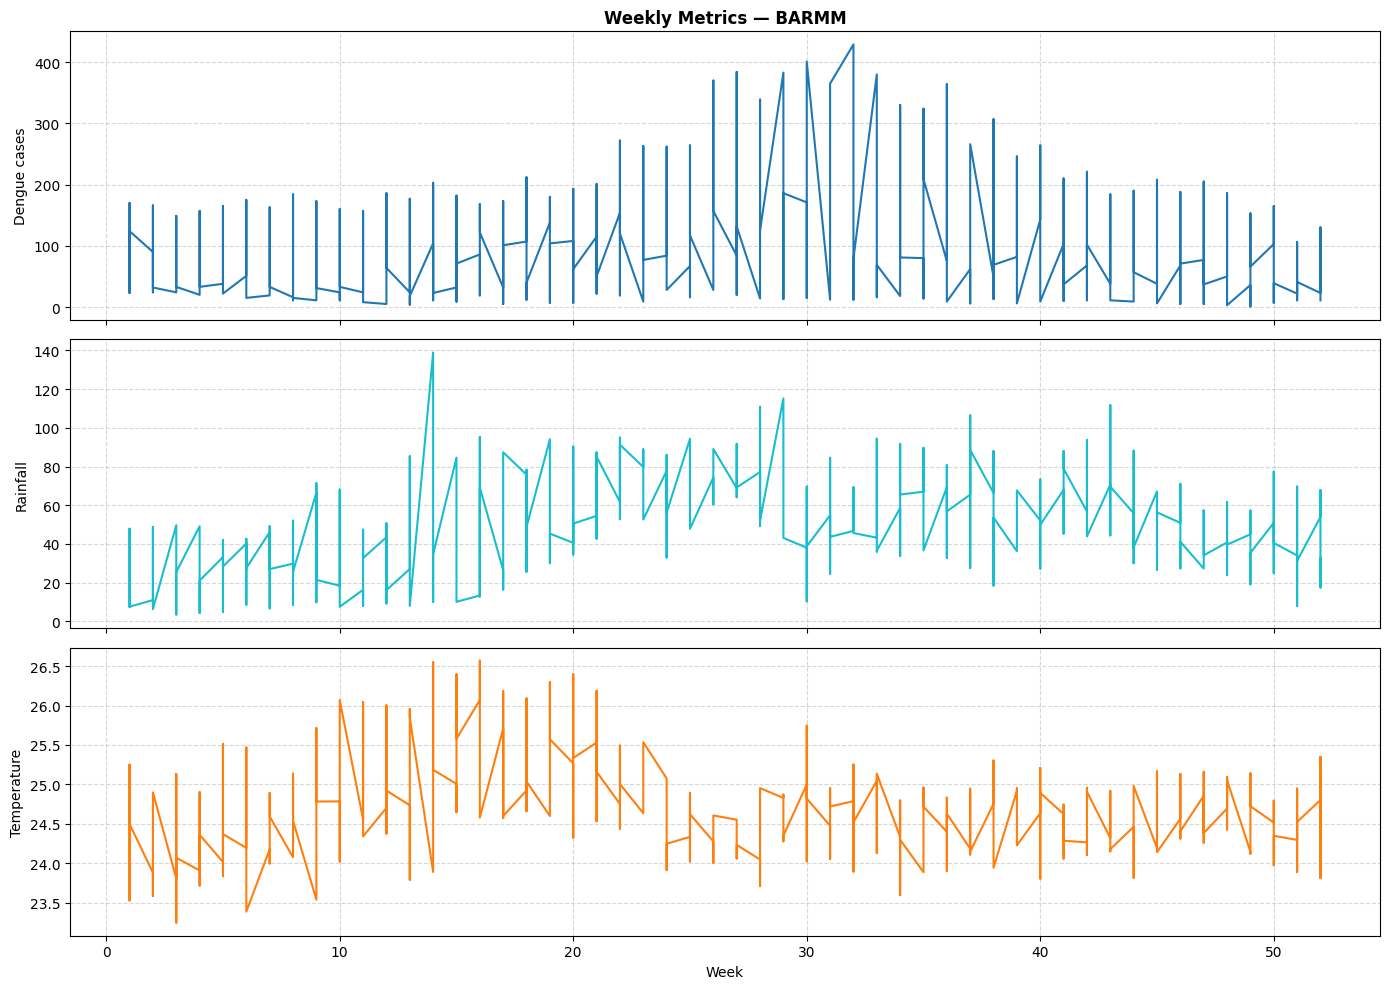

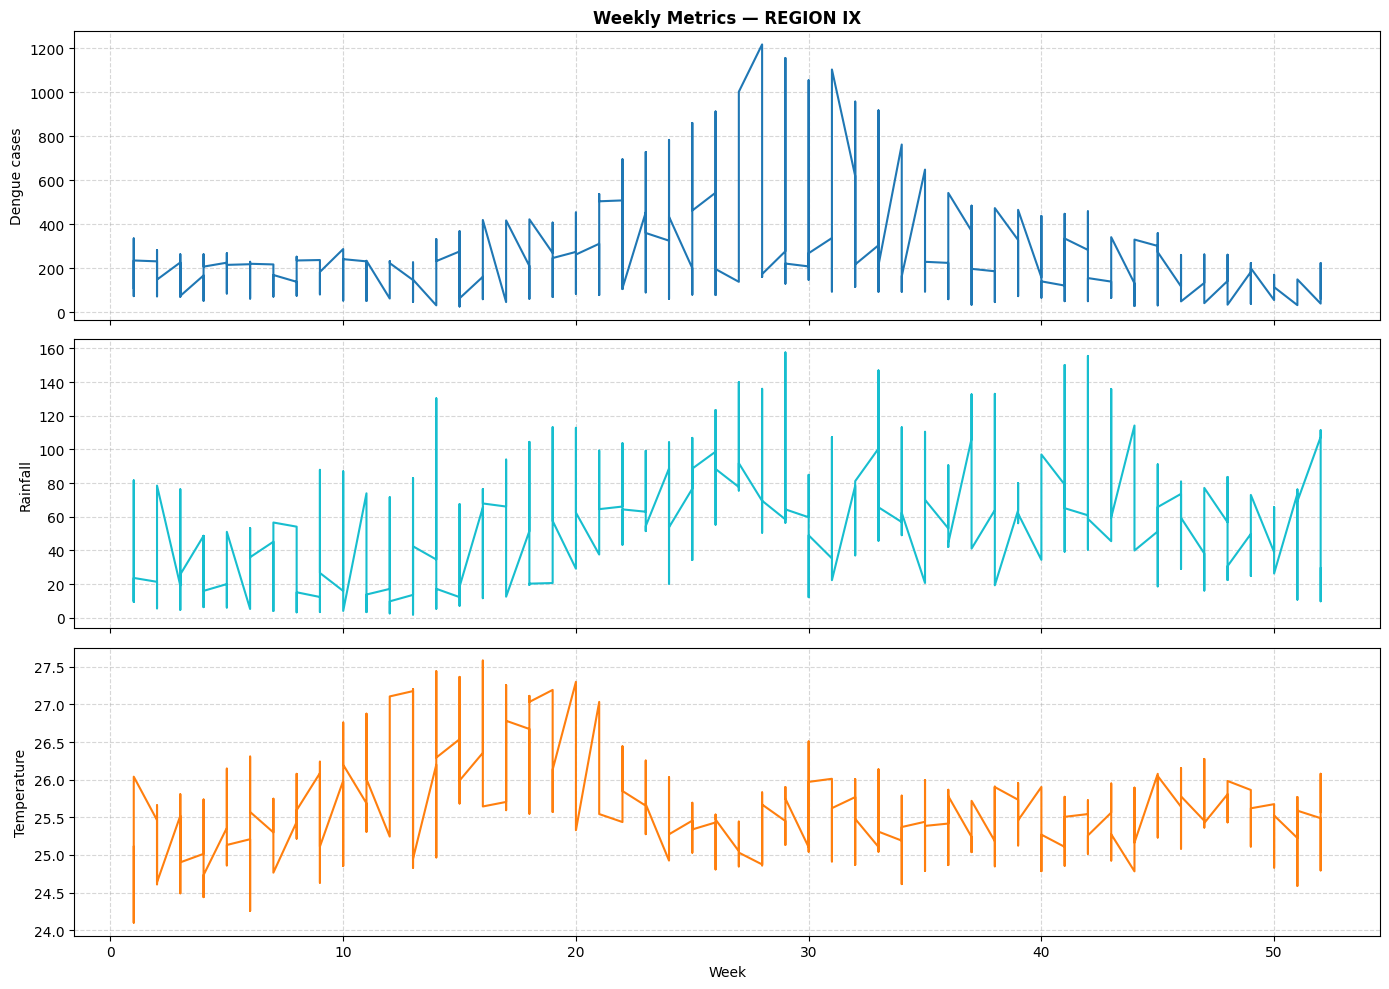

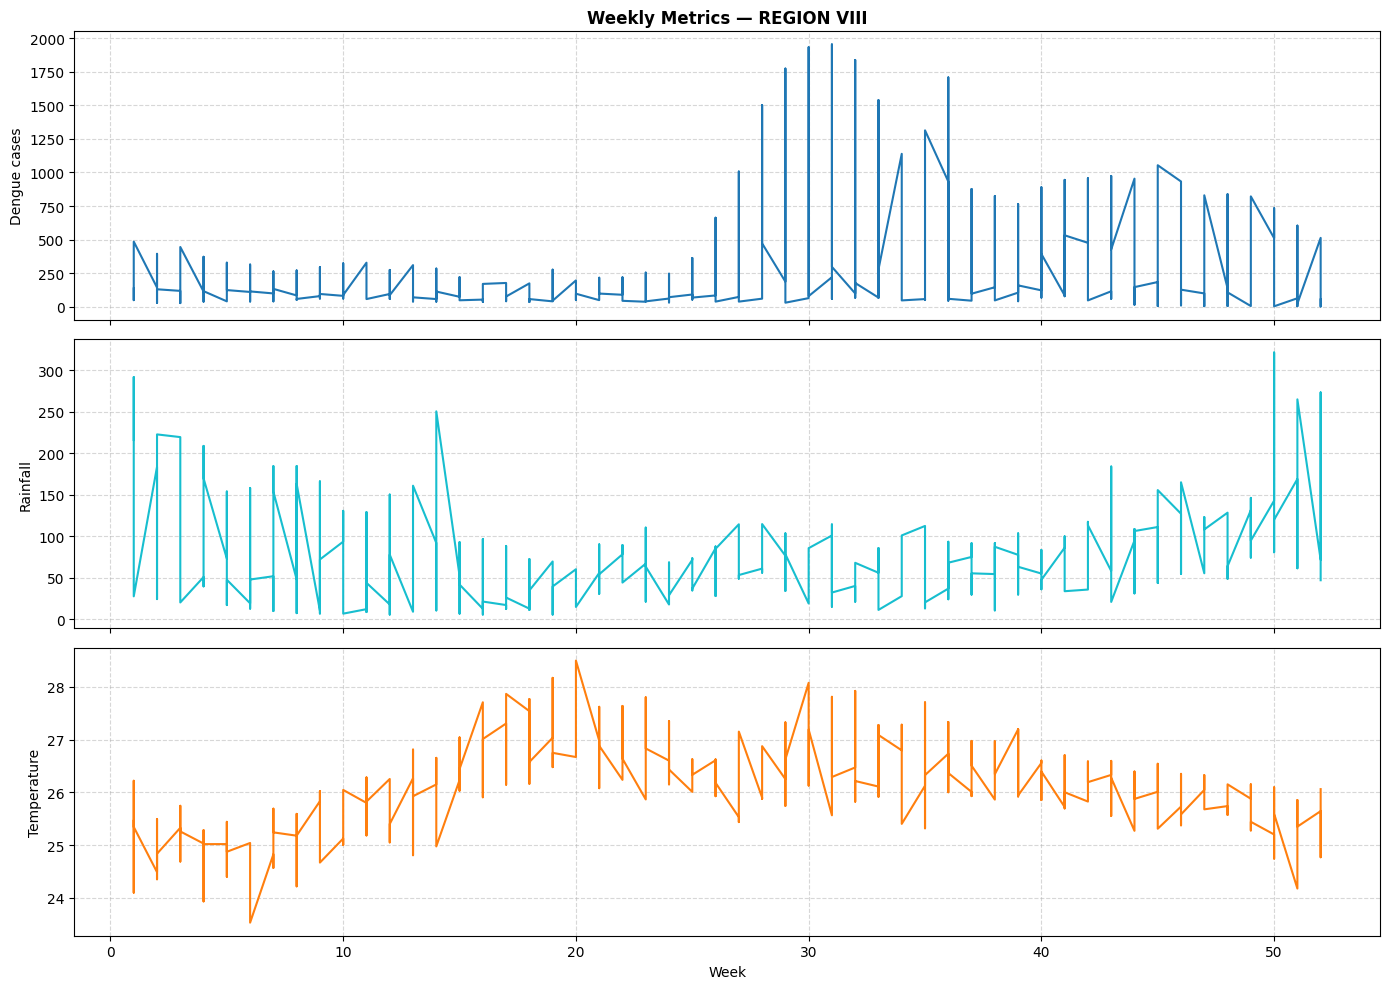

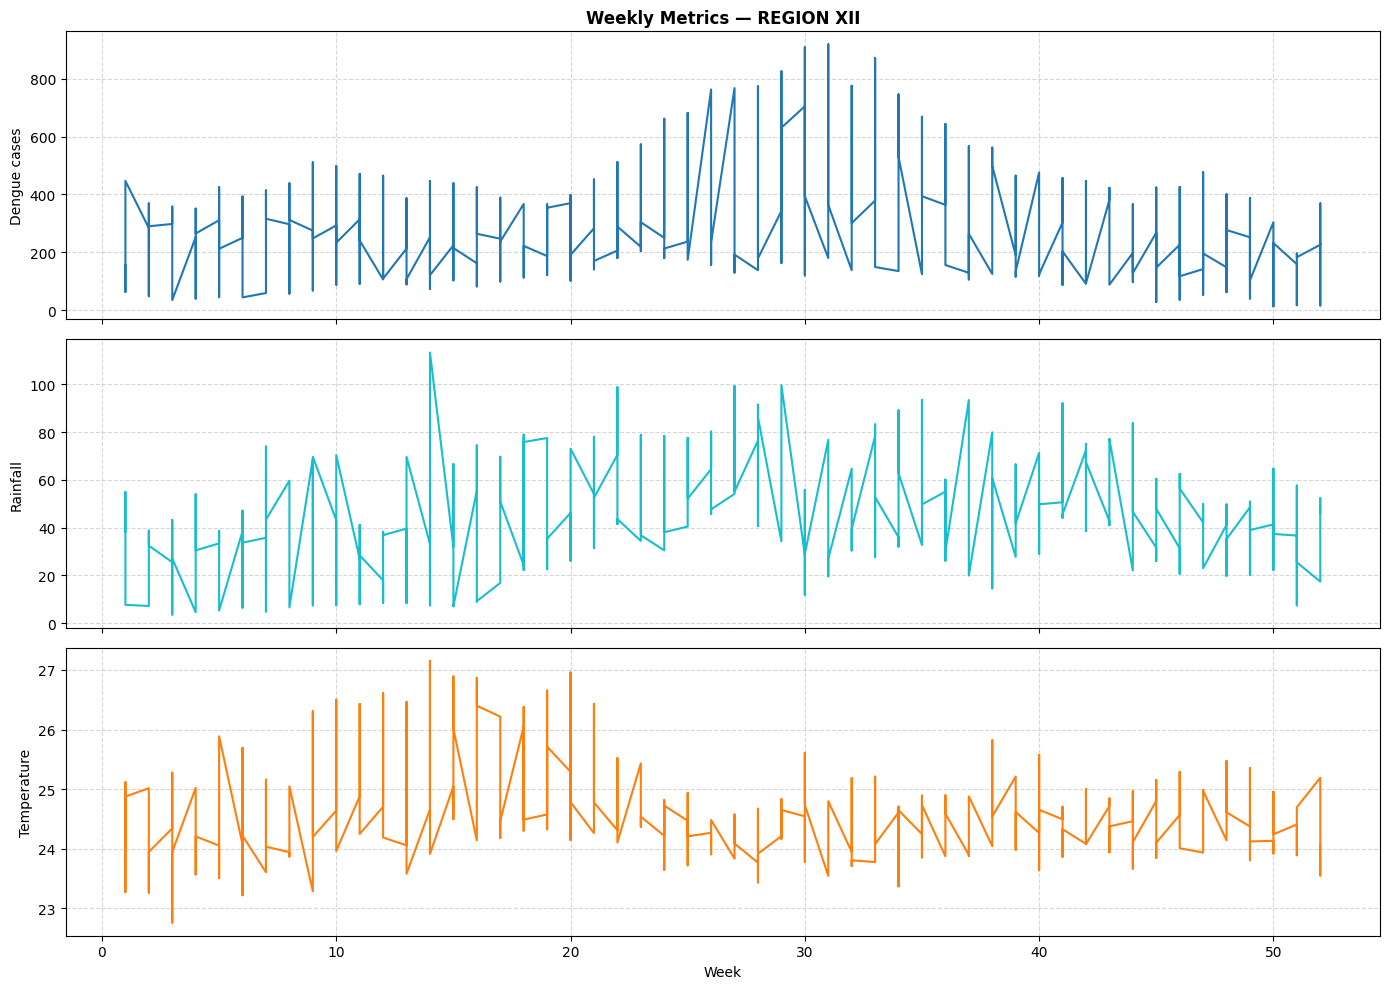

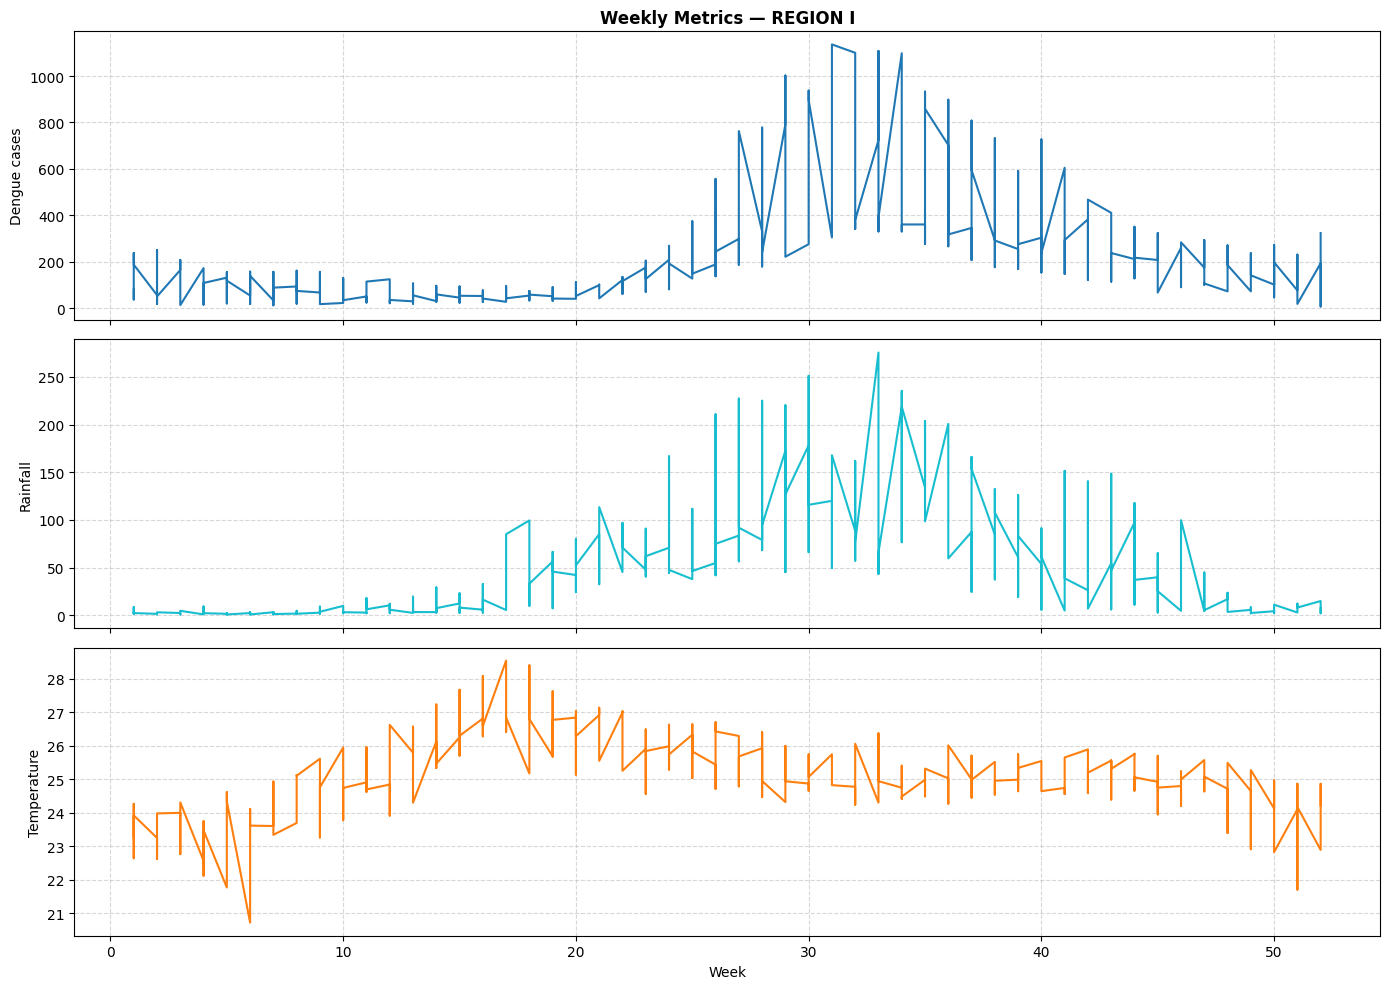

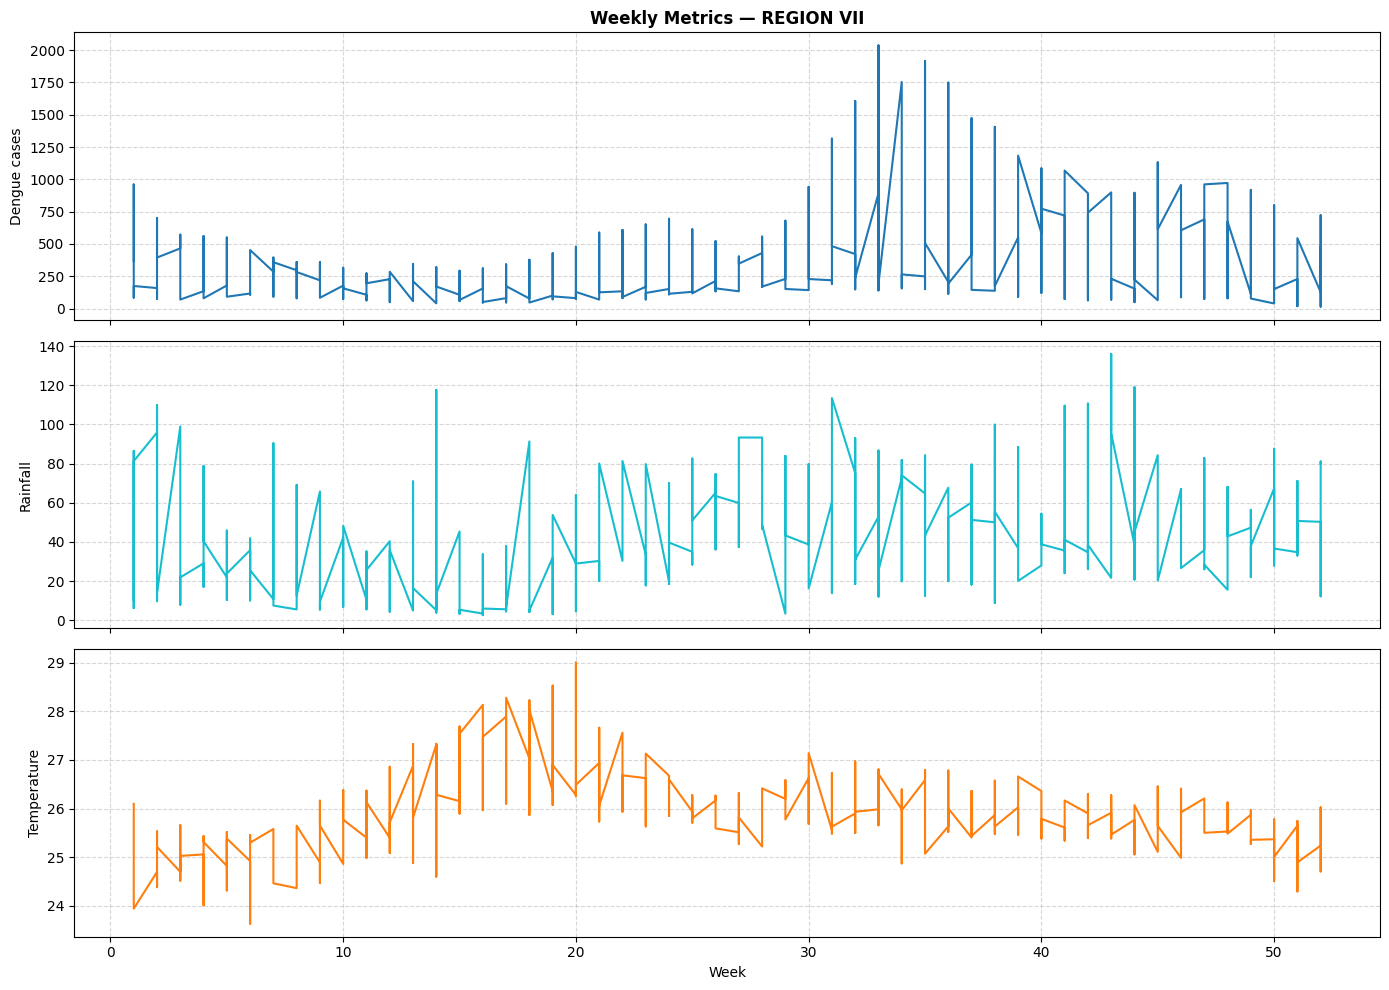

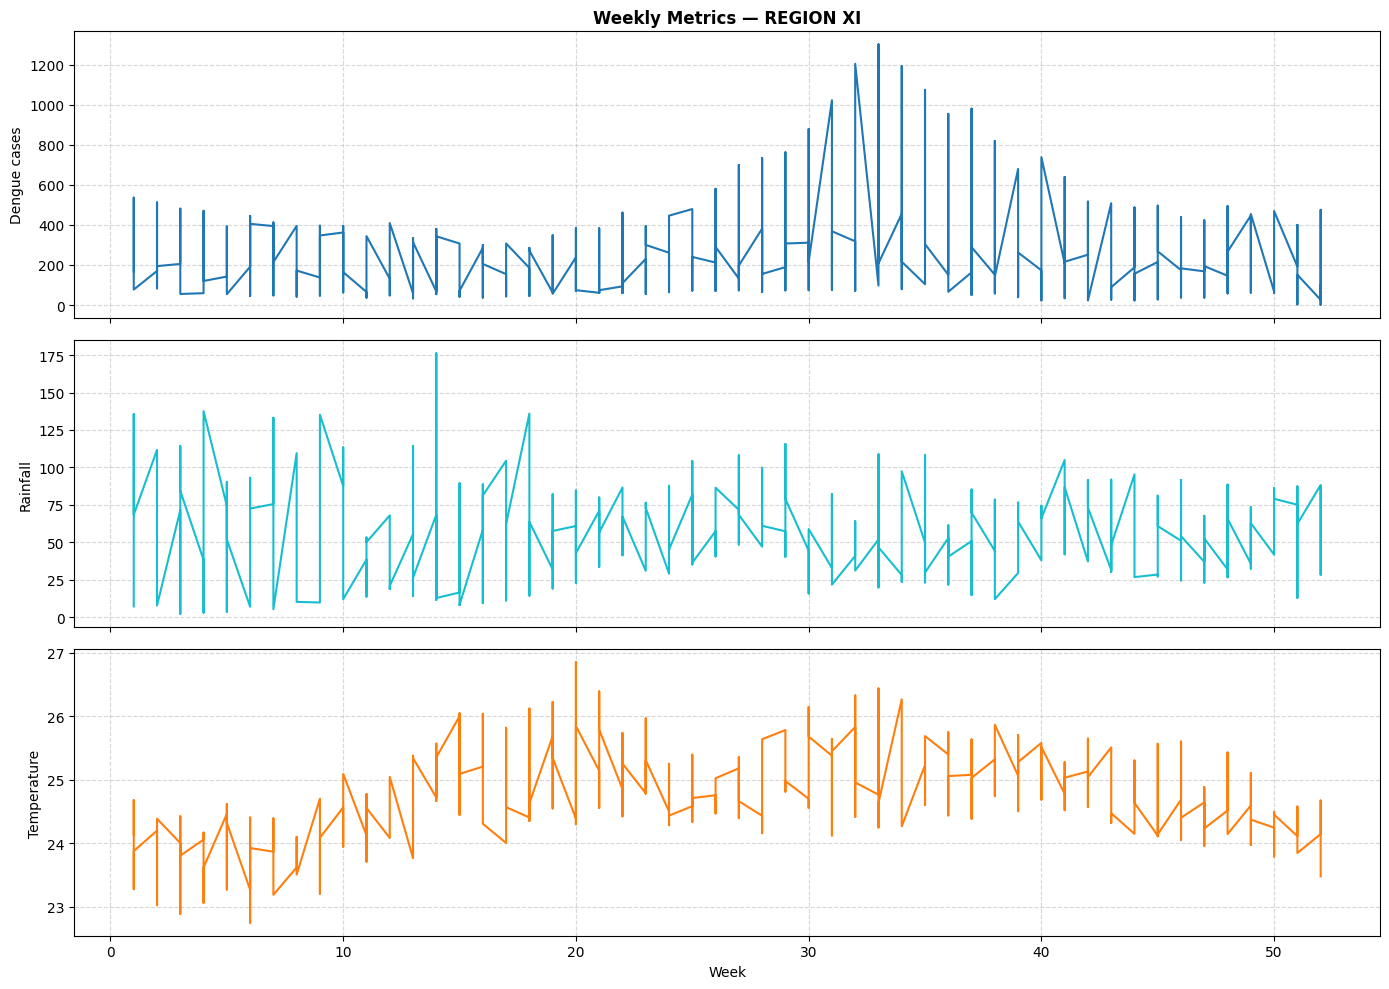

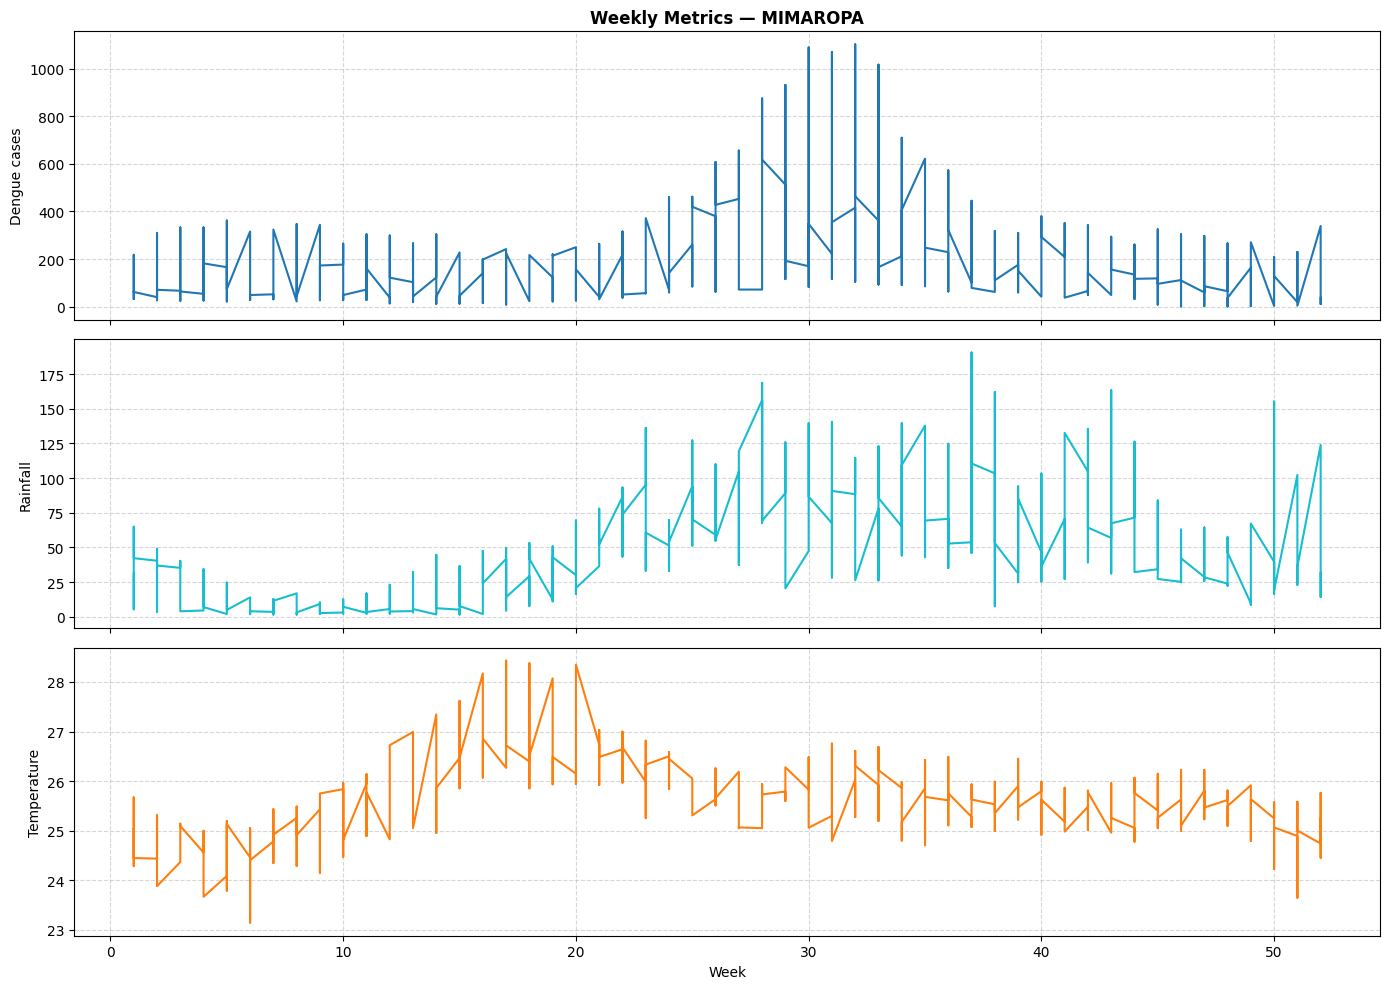

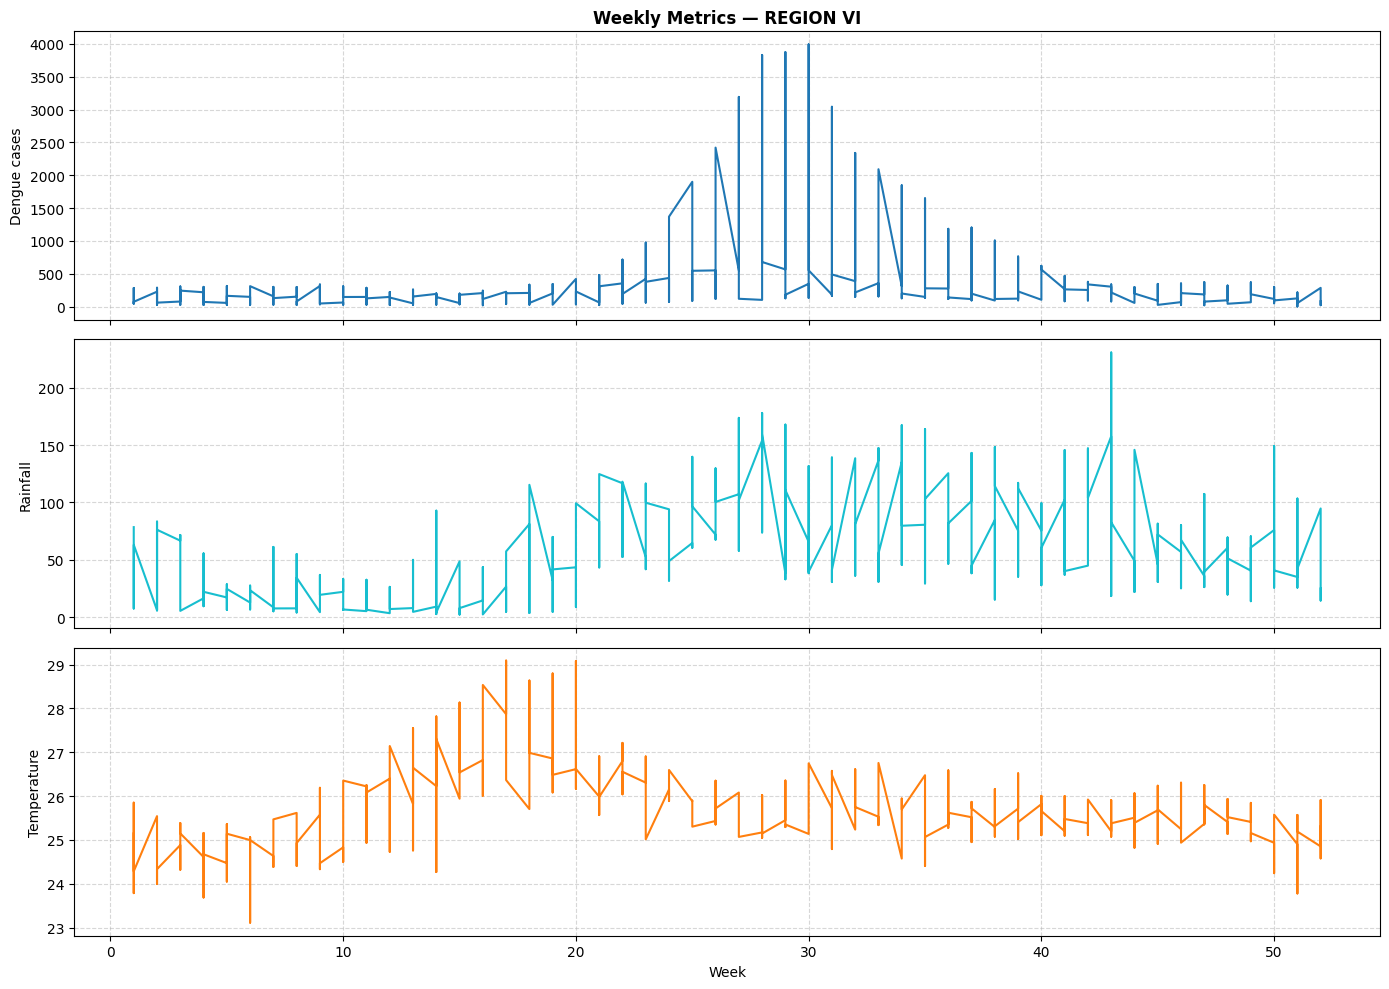

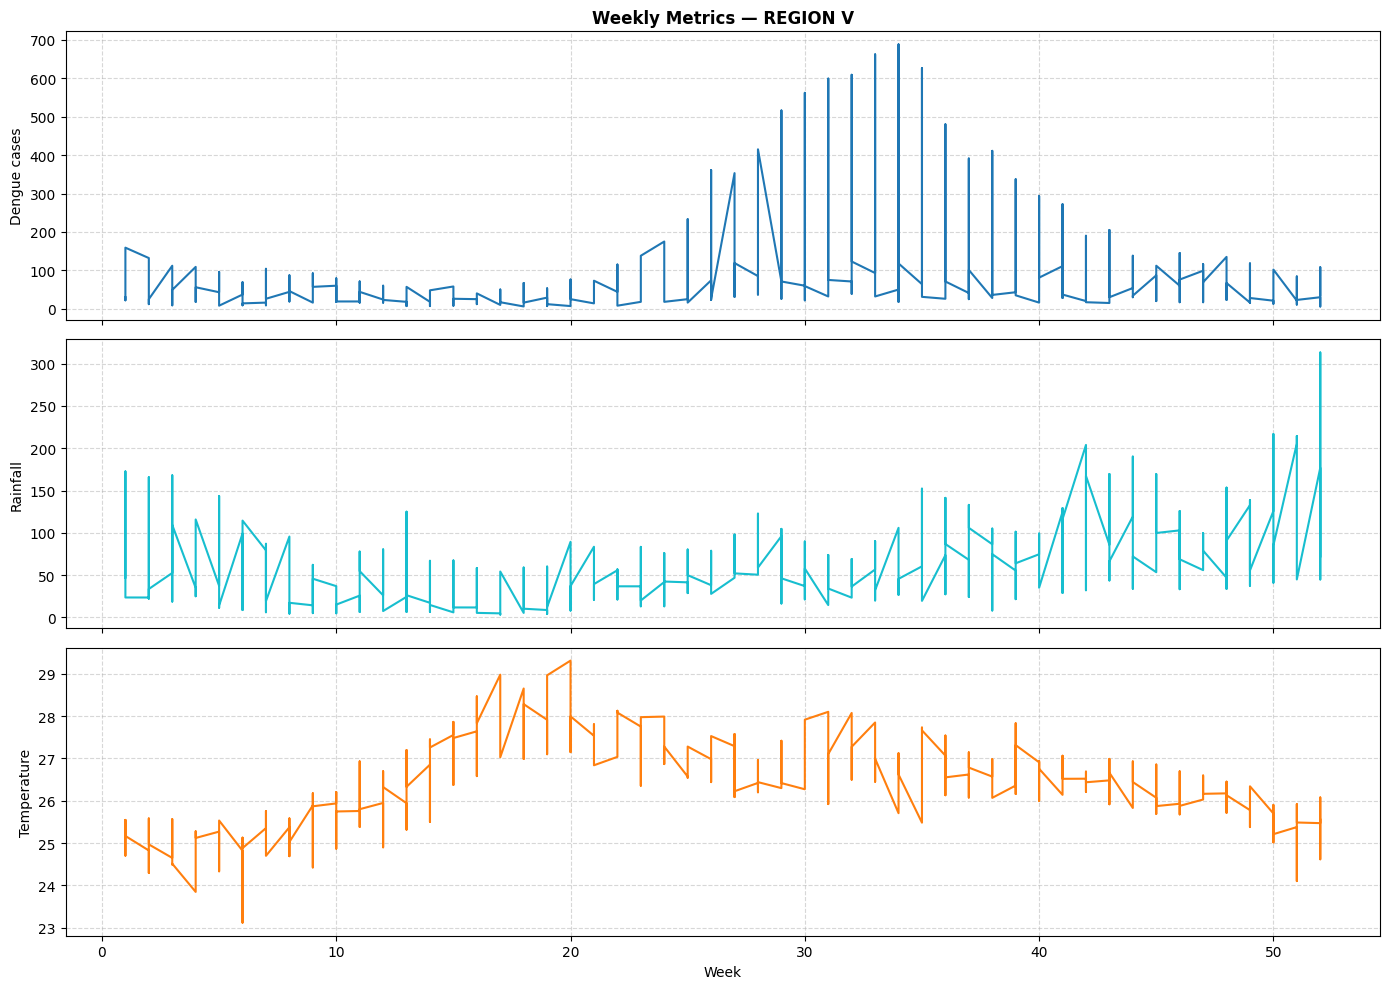

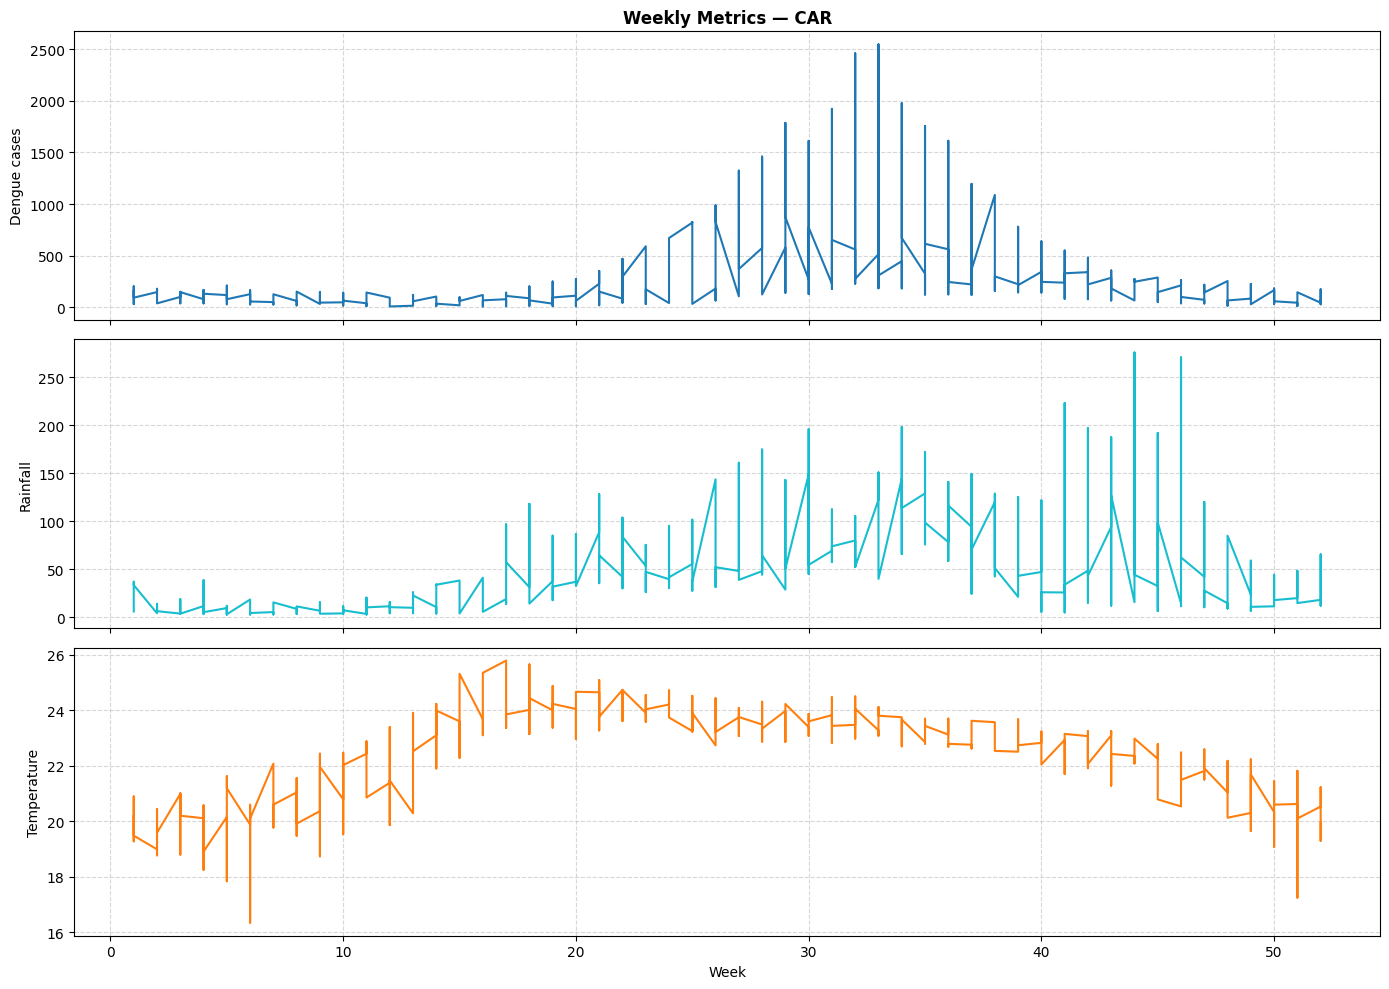

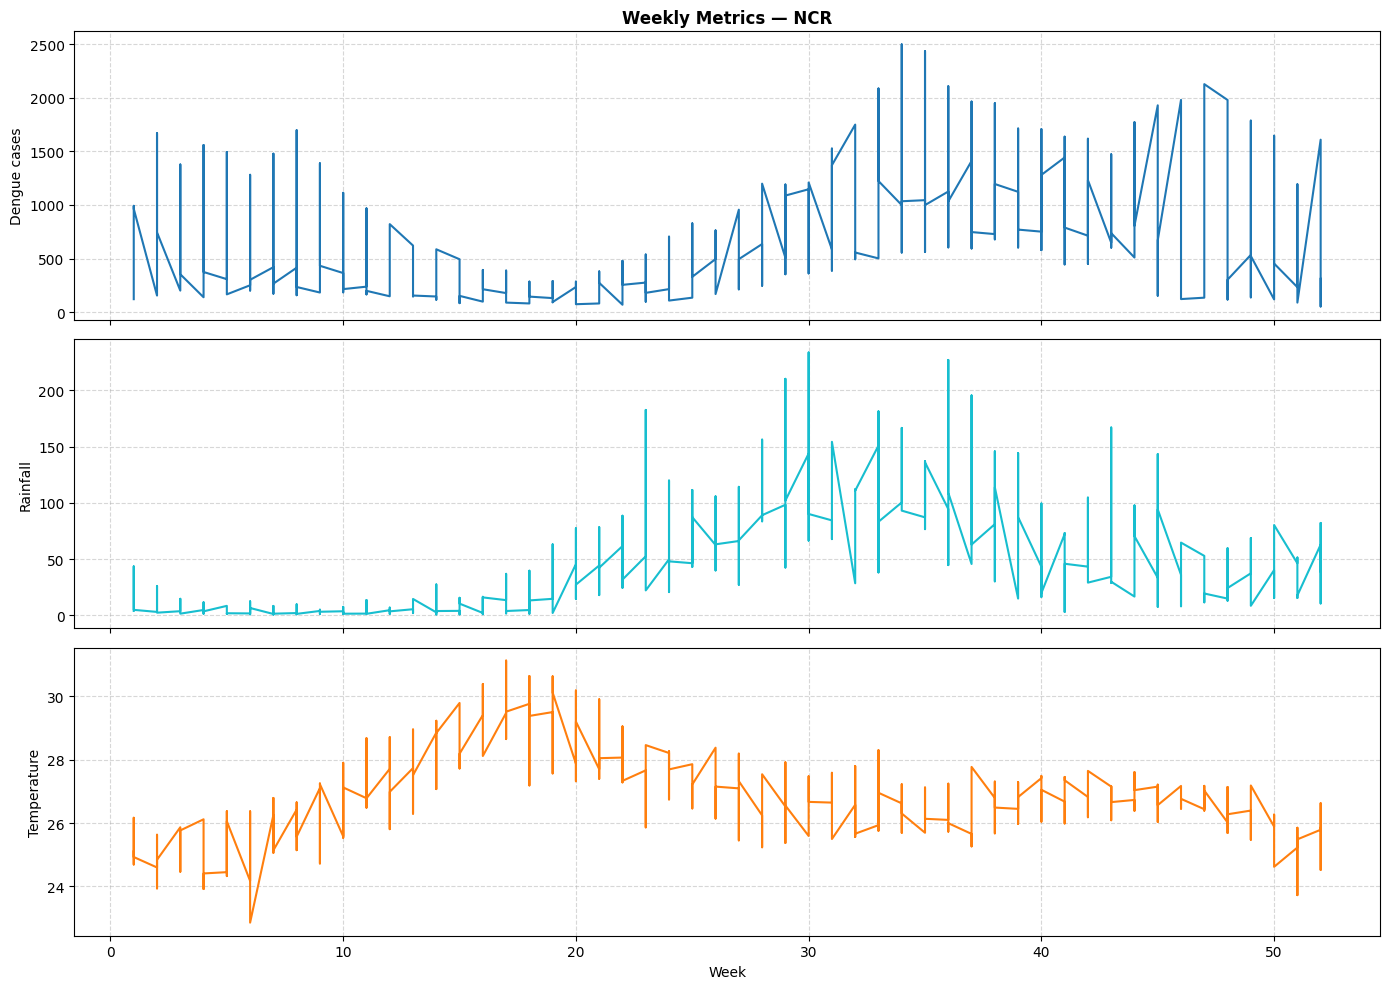

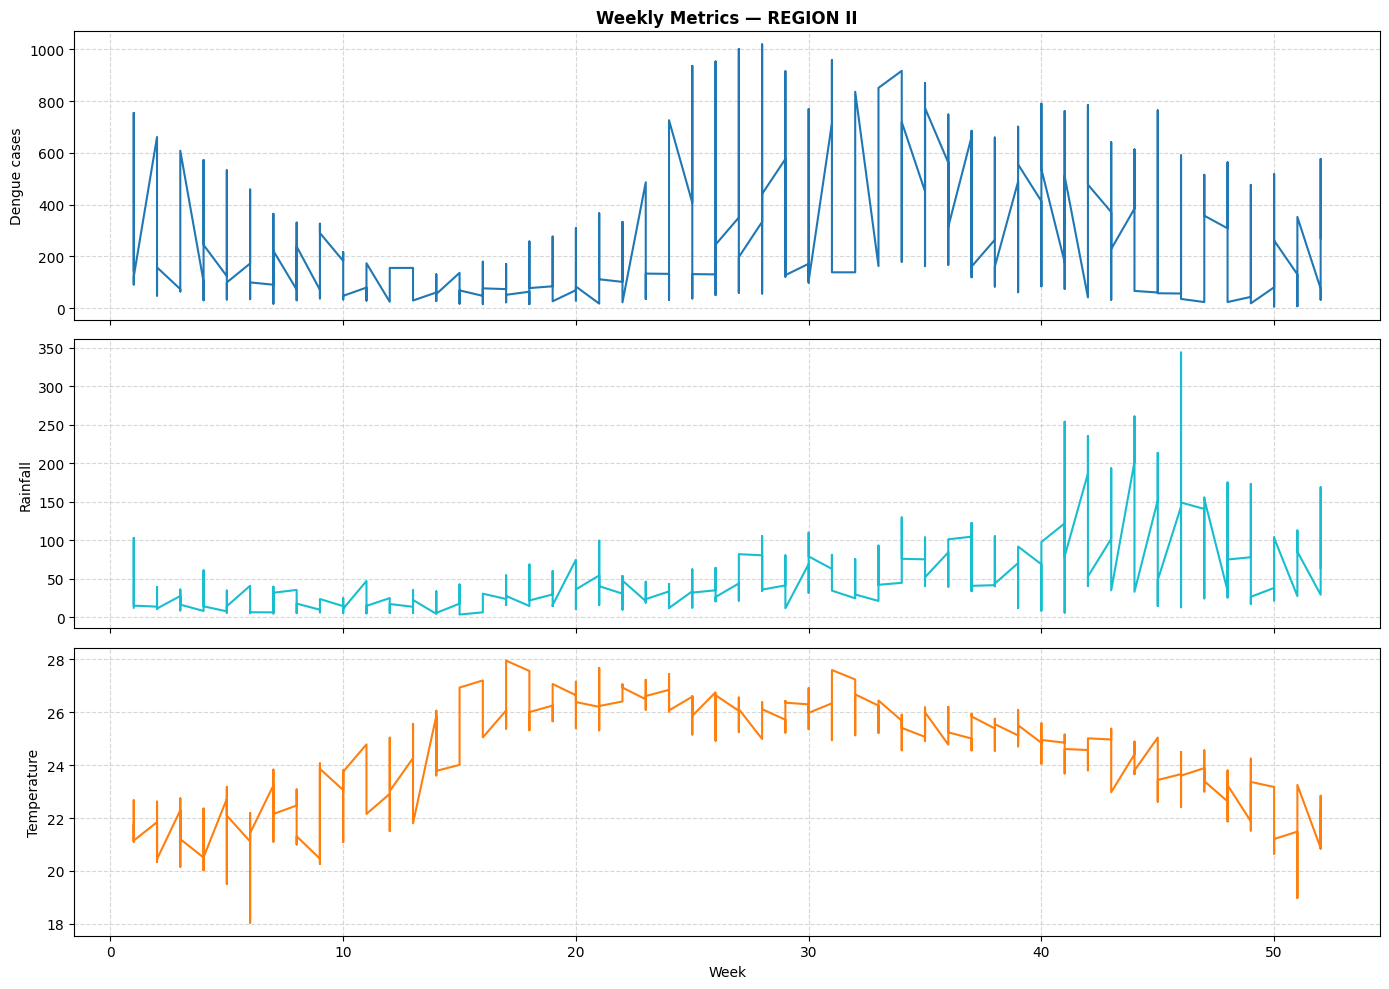

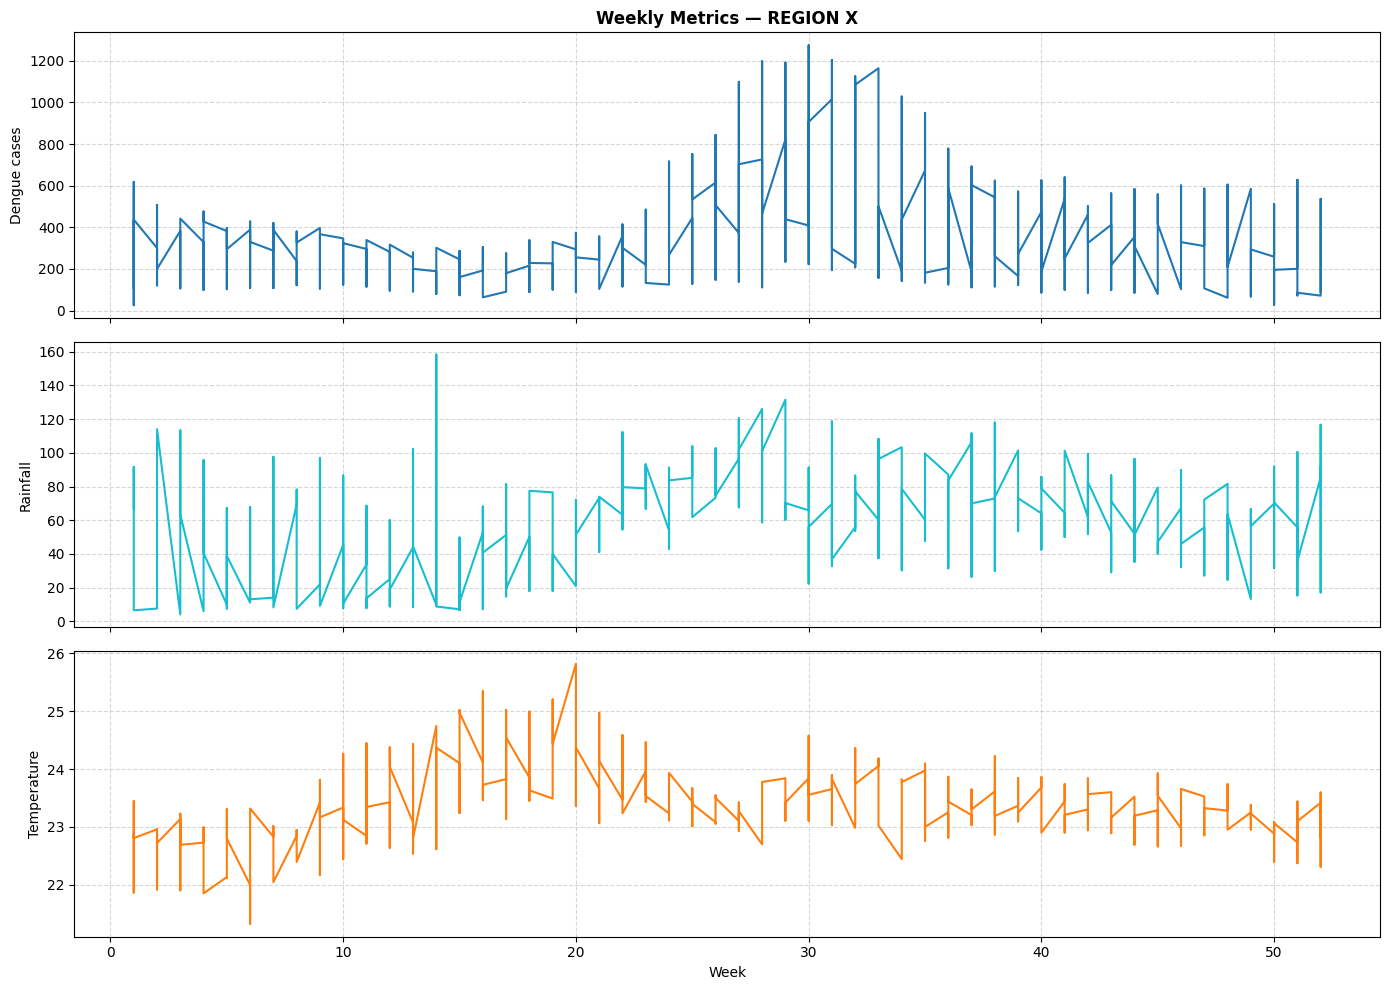

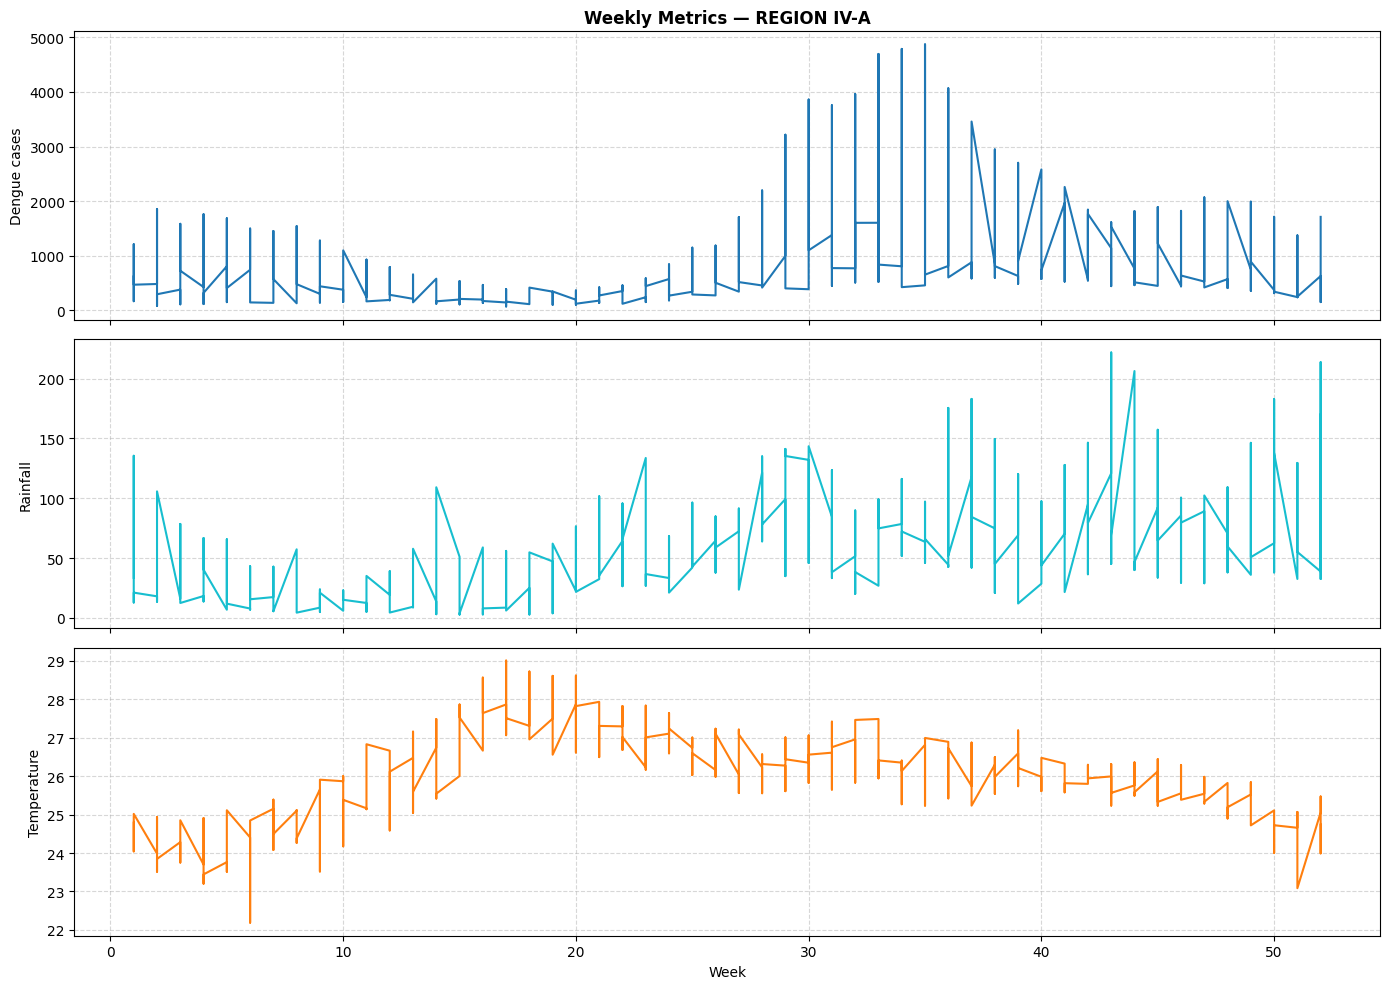

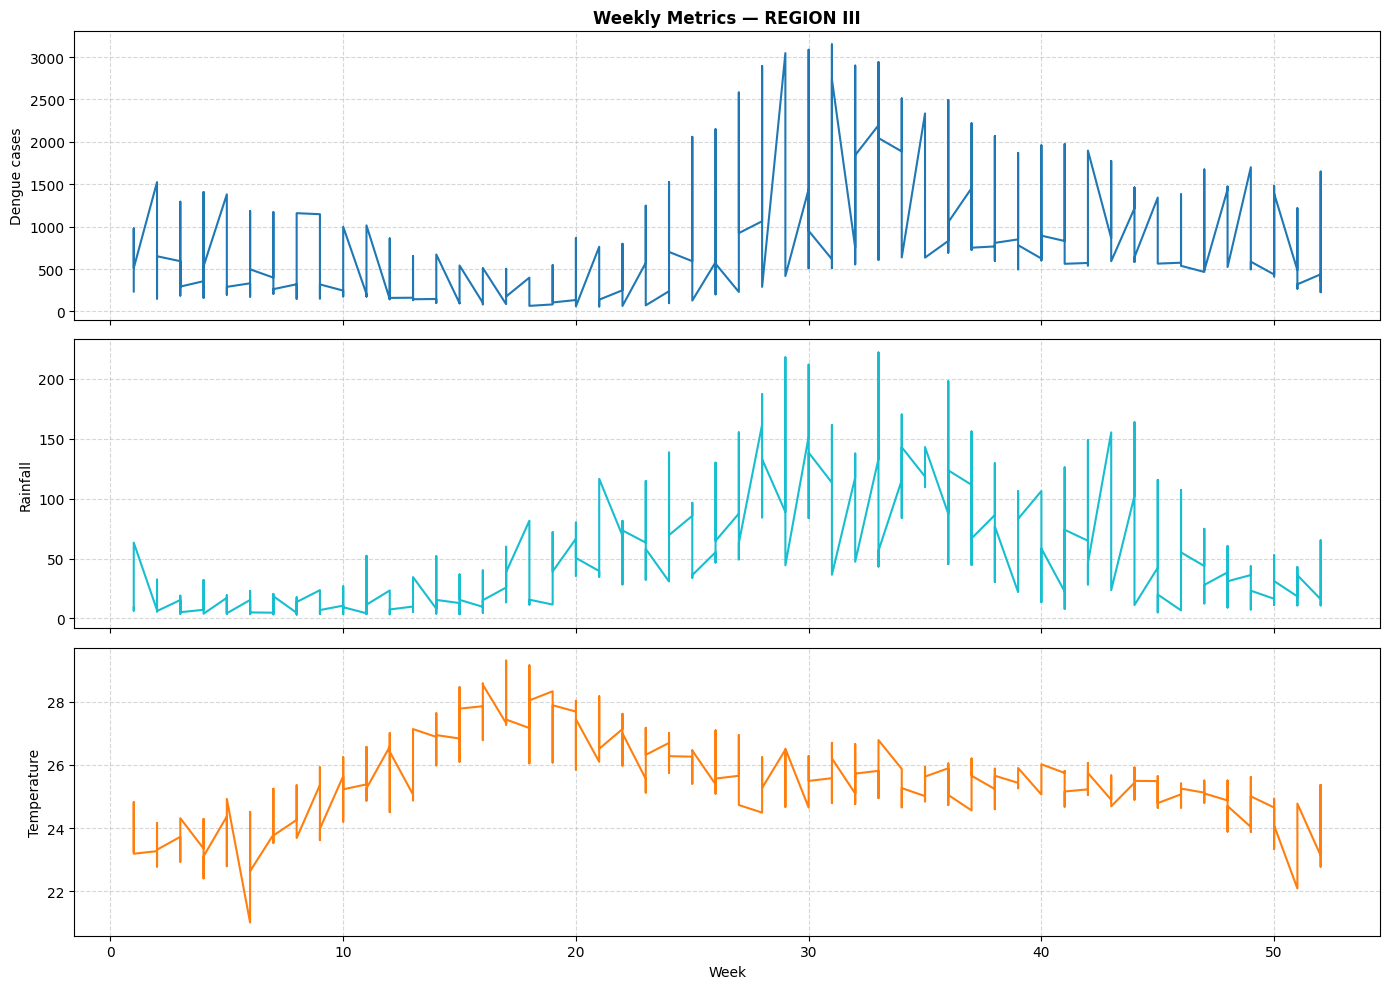

In [11]:
# Load the dataset
df = pd.read_csv("noah_regional_dengue_master.csv")

# Ensure data is sorted chronologically by week
df = df.sort_values("week")

# Loop through each region and create the 3-panel plot
for region in df["region"].unique():
    subset = df[df["region"] == region]
    
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

    # Panel 1: Dengue cases
    axes[0].plot(subset["week"], subset["dengue_cases"], color="tab:blue")
    axes[0].set_ylabel("Dengue cases")
    axes[0].set_title(f"Weekly Metrics — {region}", fontsize=12, fontweight="bold")
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # Panel 2: Rainfall
    axes[1].plot(subset["week"], subset["rainfall_estimate"], color="tab:cyan")
    axes[1].set_ylabel("Rainfall")
    axes[1].grid(True, linestyle="--", alpha=0.5)

    # Panel 3: Temperature
    axes[2].plot(subset["week"], subset["temperature_era5"], color="tab:orange")
    axes[2].set_ylabel("Temperature")
    axes[2].set_xlabel("Week")
    axes[2].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

In [12]:
regional_summary = (
    df.groupby("region")["dengue_cases"]
    .agg(["count", "mean", "median", "std", "max"])
    .sort_values("mean", ascending=False)
)

print(regional_summary)

             count        mean  median         std   max
region                                                  
REGION III     416  733.867788   554.0  625.687438  3149
REGION IV-A    416  718.173077   521.0  696.235751  4868
NCR            416  604.564904   455.0  477.614661  2500
REGION X       416  335.319712   286.0  219.886720  1274
REGION VI      416  329.600962   168.0  533.782415  3991
REGION VII     416  307.375000   190.5  298.306657  2036
REGION XII     416  271.502404   226.0  169.926065   919
REGION XI      416  250.591346   214.5  193.844855  1301
REGION II      416  239.045673   153.5  224.387435  1019
CAR            416  232.961538   137.0  322.045852  2545
REGION I       416  226.050481   151.5  226.468338  1136
REGION VIII    416  225.533654   118.0  305.245497  1954
REGION IX      416  221.918269   180.5  180.878614  1217
MIMAROPA       416  194.221154   152.0  177.841161  1102
REGION XIII    416  161.733173   126.0  131.542612   931
BARMM          416  106.507212 

--- 

# Lag Variables 

In [14]:
df = df.sort_values(["region", "week"]).copy()

case_lags = [1, 2, 3, 4]
weather_lags = [1, 2, 3, 4]

for lag in case_lags:
    df[f"cases_lag_{lag}"] = (
        df.groupby("region")["dengue_cases"].shift(lag)
    )

for col in weather_cols:
    for lag in weather_lags:
        df[f"{col}_lag_{lag}"] = (
            df.groupby("region")[col].shift(lag)
        )

df["rainfall_4week_sum"] = (
    df.groupby("region")["rainfall_estimate"]
    .transform(lambda s: s.shift(1).rolling(4).sum())
)

# Target: next week's reported dengue cases
df["target_next_week"] = (
    df.groupby("region")["dengue_cases"].shift(-1)
)

In [15]:
df["week_sin"] = np.sin(2 * np.pi * df["week"] / 52)
df["week_cos"] = np.cos(2 * np.pi * df["week"] / 52)

In [16]:

# ============================================================
# did both at the same time
# ============================================================

# Experiment A: Disease history + seasonality (baseline)
FEATURES_A = [
    "cases_lag_1",
    "cases_lag_2",
    "cases_lag_3",
    "cases_lag_4",
    "week_sin",
    "week_cos",
]

# Experiment B: Disease history + seasonality + weather
FEATURES_B = FEATURES_A + [
    "rainfall_lag_1",
    "rainfall_lag_2",
    "rainfall_lag_3",
    "rainfall_lag_4",
    "temperature_lag_1",
    "temperature_lag_2",
    "temperature_lag_3",
    "temperature_lag_4",
    "humidity_lag_1",
    "humidity_lag_2",
    "humidity_lag_3",
    "humidity_lag_4",
    "rainfall_4week_sum",
]

# Excluded from initial predictor sets
EXCLUDED_FEATURES = [
    "rainfall_approximated_flag",
    "plausibility_flag",
]

print("Experiment A — Disease History Only")
print(f"Number of features: {len(FEATURES_A)}")
print(FEATURES_A)

print("\nExperiment B — Disease History + Weather")
print(f"Number of features: {len(FEATURES_B)}")
print(FEATURES_B)


Experiment A — Disease History Only
Number of features: 6
['cases_lag_1', 'cases_lag_2', 'cases_lag_3', 'cases_lag_4', 'week_sin', 'week_cos']

Experiment B — Disease History + Weather
Number of features: 19
['cases_lag_1', 'cases_lag_2', 'cases_lag_3', 'cases_lag_4', 'week_sin', 'week_cos', 'rainfall_lag_1', 'rainfall_lag_2', 'rainfall_lag_3', 'rainfall_lag_4', 'temperature_lag_1', 'temperature_lag_2', 'temperature_lag_3', 'temperature_lag_4', 'humidity_lag_1', 'humidity_lag_2', 'humidity_lag_3', 'humidity_lag_4', 'rainfall_4week_sum']


---

## Split Data


In [18]:

dates = np.sort(df["week"].dropna().unique())

train_cutoff = dates[int(len(dates) * 0.70)]
val_cutoff = dates[int(len(dates) * 0.85)]

train_mask = df["week"] < train_cutoff
val_mask = (
    (df["week"] >= train_cutoff) &
    (df["week"] < val_cutoff)
)
test_mask = df["week"] >= val_cutoff

print("Train ends:", df.loc[train_mask, "week"].max())
print("Validation:", df.loc[val_mask, "week"].min(),
      "to", df.loc[val_mask, "week"].max())
print("Test starts:", df.loc[test_mask, "week"].min())

Train ends: 36
Validation: 37 to 44
Test starts: 45


---

## Baseline Models


In [19]:
df["naive_prediction"] = (
    df.groupby("region")["dengue_cases"].shift(1)
)

evaluation = df.loc[
    test_mask & df["target_next_week"].notna(),
    ["region", "target_next_week", "naive_prediction"]
].dropna()

In [20]:
mae = mean_absolute_error(
    evaluation["target_next_week"],
    evaluation["naive_prediction"]
)

rmse = np.sqrt(mean_squared_error(
    evaluation["target_next_week"],
    evaluation["naive_prediction"]
))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 205.36041083099906
RMSE: 341.5913560505858


In [22]:

features = [
    "cases_lag_1",
    "cases_lag_2",
    "cases_lag_3",
    "cases_lag_4",
    "week_sin",
    "week_cos",
    "rainfall_estimate_lag_1",
    "rainfall_estimate_lag_2",
    "rainfall_estimate_lag_3",
    "rainfall_estimate_lag_4",
    "temperature_era5_lag_1",
    "temperature_era5_lag_2",
    "temperature_era5_lag_3",
    "temperature_era5_lag_4",
    "specific_humidity_era5_lag_1",
    "specific_humidity_era5_lag_2",
    "specific_humidity_era5_lag_3",
    "specific_humidity_era5_lag_4",
    "rainfall_4week_sum",
]

model_data = df.dropna(
    subset=features + ["target_next_week", "week"]
).copy()

train = model_data[model_data["week"] < train_cutoff]
val = model_data[
    (model_data["week"] >= train_cutoff) &
    (model_data["week"] < val_cutoff)
]
test = model_data[model_data["week"] >= val_cutoff]

rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf.fit(train[features], train["target_next_week"])

predictions = np.clip(rf.predict(test[features]), 0, None)

print("Test MAE:",
      mean_absolute_error(test["target_next_week"], predictions))
print("Test RMSE:",
      np.sqrt(mean_squared_error(test["target_next_week"], predictions)))

Test MAE: 218.92869929140002
Test RMSE: 295.5796260593968


In [28]:



model_data = df.dropna(
    subset=features + ["target_next_week", "week"]
).copy()

train = model_data[model_data["week"] < train_cutoff]
val = model_data[
    (model_data["week"] >= train_cutoff) &
    (model_data["week"] < val_cutoff)
]
test = model_data[model_data["week"] >= val_cutoff]

# Initialize XGBoost Regressor
model = xgb.XGBRegressor(
    n_estimators=300,
    min_child_weight=3,  # Analogous regularization parameter for leaf nodes
    random_state=42,
    n_jobs=-1
)

model.fit(train[features], train["target_next_week"])

predictions = np.clip(model.predict(test[features]), 0, None)

print("Test MAE:",
      mean_absolute_error(test["target_next_week"], predictions))
print("Test RMSE:",
      np.sqrt(mean_squared_error(test["target_next_week"], predictions)))

Test MAE: 252.19942638653666
Test RMSE: 352.3879008894673


--- 

## Explain using SHAP

/home/bsdsba2027/bmanatad/.conda/envs/lmeval/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


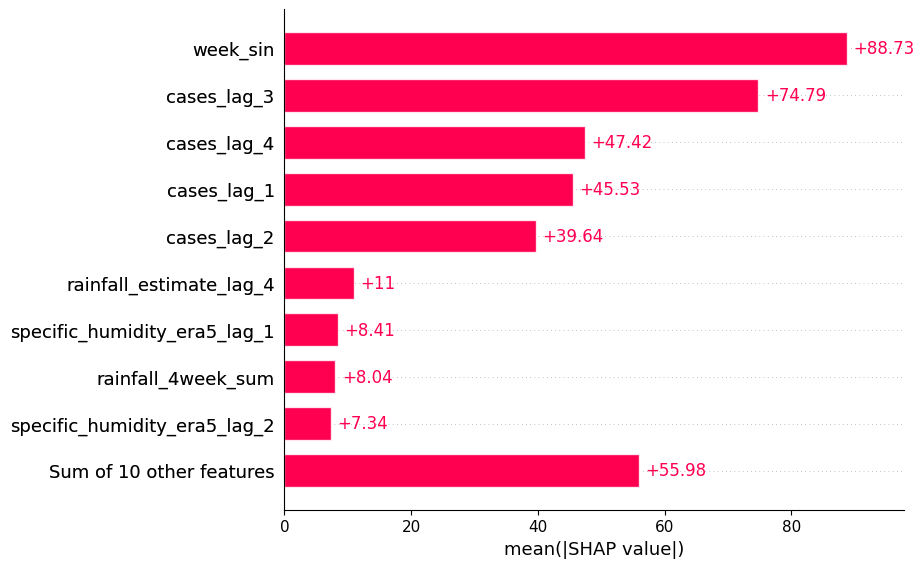

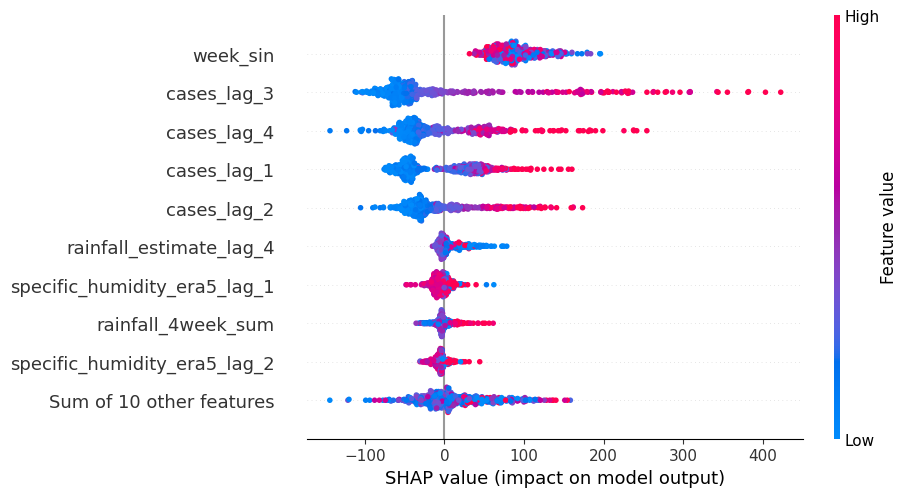

In [29]:
import shap

explainer = shap.TreeExplainer(rf)
sample = test[features].sample(
    min(500, len(test)),
    random_state=42
)

shap_values = explainer(sample)

shap.plots.bar(shap_values)
shap.plots.beeswarm(shap_values)

---

## Converting predictions into risk categories

- assuming we calculate region-specific 75th and 90th percentiles using training-period observations only

In [44]:

# Combine test-set metadata with model predictions
forecast_results = test[
    ["region", "year", "week"]
].copy()

forecast_results["predicted_cases"] = np.asarray(
    predictions
).flatten()

# Prevent negative predicted case counts
forecast_results["predicted_cases"] = (
    forecast_results["predicted_cases"].clip(lower=0)
)

# Assign risk categories
forecast_results["risk_level"] = forecast_results.apply(
    classify_risk, axis=1
)

# Round case counts for easier reporting
forecast_results["predicted_cases_rounded"] = (
    forecast_results["predicted_cases"].round().astype(int)
)

# Display results
print(
    forecast_results[
        [
            "region",
            "year",
            "week",
            "predicted_cases_rounded",
            "risk_level",
        ]
    ].head(10)
)


    region  year  week  predicted_cases_rounded risk_level
44   BARMM  2016    45                       46       High
200  BARMM  2019    45                      146  Very High
304  BARMM  2023    45                      181  Very High
252  BARMM  2022    45                      221  Very High
356  BARMM  2024    45                      134  Very High
408  BARMM  2025    45                      226  Very High
148  BARMM  2018    45                        7        Low
96   BARMM  2017    45                      175  Very High
45   BARMM  2016    46                       54  Very High
97   BARMM  2017    46                      123  Very High


In [45]:

risk_summary = (
    forecast_results["risk_level"]
    .value_counts()
    .reindex(
        ["Low", "Moderate", "High", "Very High"],
        fill_value=0
    )
    .rename_axis("risk_level")
    .reset_index(name="number_of_observations")
)

print(risk_summary)


  risk_level  number_of_observations
0        Low                       1
1   Moderate                       2
2       High                       4
3  Very High                    1064


In [46]:
# change name depending on region

region_forecast = forecast_results[
    forecast_results["region"] == "REGION III"
].sort_values(["year", "week"])

print(region_forecast.head(20))


          region  year  week  predicted_cases risk_level  \
2540  REGION III  2016    45       705.907349  Very High   
2541  REGION III  2016    46       860.739380  Very High   
2542  REGION III  2016    47       387.655884  Very High   
2543  REGION III  2016    48       501.559753  Very High   
2544  REGION III  2016    49       599.611145  Very High   
2545  REGION III  2016    50       887.688416  Very High   
2546  REGION III  2016    51       481.649902  Very High   
2547  REGION III  2016    52       413.020844  Very High   
2592  REGION III  2017    45       732.587158  Very High   
2593  REGION III  2017    46       359.382660  Very High   
2594  REGION III  2017    47       514.547119  Very High   
2595  REGION III  2017    48       792.415283  Very High   
2596  REGION III  2017    49       612.087585  Very High   
2597  REGION III  2017    50       644.064941  Very High   
2598  REGION III  2017    51       798.458130  Very High   
2599  REGION III  2017    52       631.2